# 02 · Análisis causal: ¿el fuego abre la puerta al cambio de uso del suelo?
**Premio MapBiomas Chile, 1.ª edición — Categoría Análisis Técnico o Científico**

**Pregunta.** Entre píxeles con la misma cobertura natural o silvícola el año previo, ¿cuánto aumenta el incendio la probabilidad de terminar como agricultura, pastura o infraestructura (*cambio de uso*), por encima de lo que habría ocurrido sin fuego?

**Diseño.** Diferencias en diferencias apiladas por cohorte de incendio (2014–2022) con emparejamiento por puntaje de propensión dentro de región, sobre la trayectoria anual 1999–2024 de MapBiomas Chile Colección 2 y las cicatrices de MapBiomas Fuego Colección 1. Inferencia con bootstrap por bloques espaciales de ~10 km.

**Corrección clave.** El producto Fuego borra la quema en píxeles que quedan como infraestructura, agricultura, pastura o agua durante 4 años desde el incendio. Se aplica una regla simétrica de exclusión y se reportan **cotas inferior y superior** del efecto.

> Si `FUENTE = "simulado"`, el notebook corre completo con un paisaje sintético de efecto conocido (validación del estimador). Con `FUENTE = "real"` usa los CSV exportados por el notebook 01.

## 0. Configuración

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

import fuegocausal as fc
from simular import simular, att_verdadero

warnings.filterwarnings("ignore")
FUENTE = "real"                  # "real" = datos MapBiomas extraídos; "simulado" = validación
COLECCION = 2                    # 1 = Cobertura Col. 1 (2000-2022, GeoTIFF públicos); 2 = Col. 2 vía Earth Engine
RUTA_MUESTRAS = "datos/muestra_*.csv"
RUTA_AREAS = "datos/areas_quemadas.csv"
N_BOOT = 300
if FUENTE == "real" and COLECCION == 1:
    fc.usar_coleccion1(2005, 2022)
    COHORTES = range(2014, 2022)
elif FUENTE == "real" and COLECCION == 2:
    COHORTES = range(2014, 2022)        # cohortes con censura consistente del filtro de Fuego (2022-2023 se analizan aparte)
else:
    COHORTES = range(2014, 2023)
VENTANA_POST = (1, 3)            # años post-incendio para el efecto resumen (cohortes balanceadas: g + 3 <= último año)
SUF = "_col2" if (FUENTE == "real" and COLECCION == 2) else ""
FIG, RES = f"figuras{SUF}/", f"resultados{SUF}/"
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.family": "DejaVu Sans"})
C_TRAT, C_CTRL, C_INF, C_SUP = "#B23A1F", "#3B6E8F", "#B23A1F", "#D98C1E"


## 1. Datos

In [2]:
verdad = None
if FUENTE == "real" and COLECCION == 2:
    exec(open("prep_col2.py").read())
elif FUENTE == "real":
    archivos = sorted(glob.glob(RUTA_MUESTRAS))
    assert archivos, f"No hay archivos en {RUTA_MUESTRAS}"
    df = pd.concat([pd.read_csv(a) for a in archivos], ignore_index=True)
    areas = (pd.read_csv(RUTA_AREAS).rename(columns={"sum": "ha"})
             if os.path.exists(RUTA_AREAS) else None)
else:
    df, verdad = simular(n=150_000, semilla=2026)
    areas = None

if FUENTE == "real" and COLECCION == 1:
    # Distancias calculadas dentro de ventanas de ~30 km: sin la clase en la ventana -> valor centinela.
    # Se acotan al máximo medible (diagonal de la ventana, ~43 km).
    for c in ["dist_urb", "dist_agr", "dist_silv"]:
        df[c] = df[c].clip(upper=43_000)

    # Región administrativa oficial (MapBiomas Chile, nivel político 2), por intersección punto-polígono.
    from asignar_regiones import asignar
    df["region"] = asignar(df.lon.to_numpy(), df.lat.to_numpy())
    if areas is not None:   # para escalar a hectáreas basta el total por cohorte
        areas = areas.groupby("cohorte", as_index=False)["ha"].sum().assign(region="Total")

faltan = [c for c in fc.COLS_LULC + ["fire_first", "fire_count", "lon", "lat"] if c not in df]
assert not faltan, f"Columnas faltantes: {faltan}"
df = df.reset_index(drop=True)
print(f"Píxeles: {len(df):,} | quemados (primer incendio 2013-2025): {(df.fire_first > 0).sum():,} "
      f"| nunca quemados: {(df.fire_count == 0).sum():,}")
df.fire_first[df.fire_first > 0].value_counts().sort_index().rename("píxeles quemados por año").to_frame().T

Píxeles: 251,680 | quemados (primer incendio 2013-2025): 83,944 | nunca quemados: 167,736


fire_first,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
píxeles quemados por año,6146,7611,3774,30157,2675,2160,3089,4982,5558,17792


### 1.1 Cobertura del año previo al incendio

In [3]:
L = fc.matriz_lulc(df)
q = df.fire_first.between(min(COHORTES), max(COHORTES)).to_numpy()
prev = L[q, (df.fire_first[q] - 1 - fc.LULC_Y0).to_numpy()]
tabla_prev = (pd.Series(prev).map(fc.CLASES).value_counts(normalize=True)
              .rename("proporción").to_frame().style.format("{:.1%}"))
tabla_prev

,proporción
Matorral,43.2%
Silvicultura,36.5%
Bosque secundario,10.0%
Bosque primario,7.1%
Pastizal,1.2%
Agricultura,1.1%
Bosque,0.7%
Pastura,0.2%
Bosque achaparrado,0.0%
Humedal,0.0%


## 2. Pesos muestrales y covariables

In [4]:
if "w_muestral" not in df:
    df = fc.pesos_muestrales(df, areas)
if "bloque" not in df:
    df = fc.preparar_covariables(df)
if "dist_road" not in df or (df["dist_road"] < 0).all():   # sin red vial: no usar esa covariable
    fc.COVARIABLES = [c for c in fc.COVARIABLES if c != "log_dist_road"]
print("Covariables de emparejamiento:", fc.COVARIABLES)

Covariables de emparejamiento: ['elev', 'slope', 'northness', 'eastness', 'log_dist_road', 'log_dist_urb', 'log_dist_agr', 'log_dist_silv', 'lat', 'lon', 'n_cambios_pre']


## 3. Emparejamiento por cohorte × cobertura basal
Dos reglas para los controles, que acotan el efecto real:
* **Conservadora (cota inferior):** mantiene controles que se convierten de forma estable después de *g*; algunos pueden ser incendios borrados por el filtro de Fuego, lo que infla la conversión de los controles.
* **Estricta (cota superior):** descarta los controles que el filtro habría borrado entre *g+1* y *g+5*; quita incendios ocultos, pero también conversiones genuinas sin fuego.

In [5]:
res = {}
for regla in ["conservadora", "estricta"]:
    print(f"\n=== Regla {regla} ===")
    pares, bal = fc.panel_apilado(df, cohortes=COHORTES, regla_control=regla, verbose=(regla == "conservadora"))
    res[regla] = {"pares": pares, "balance": bal}
    print(f"Tratados emparejados: {pares.i_trat.nunique():,} de {bal.drop_duplicates(['cohorte','grupo']).n_trat.sum():,}")
pares = res["conservadora"]["pares"]; bal = res["conservadora"]["balance"]


=== Regla conservadora ===


  cohorte 2014 | Bosque           | tratados   1153 | controles   42165 | emparejados   1153


  cohorte 2014 | Matorral         | tratados   3308 | controles   69056 | emparejados   3308
  cohorte 2014 | Pastizal/estepa  | tratados     67 | controles    8687 | emparejados     67


  cohorte 2014 | Silvicultura     | tratados   1282 | controles   31816 | emparejados   1282


  cohorte 2015 | Bosque           | tratados   1170 | controles   42619 | emparejados   1170


  cohorte 2015 | Matorral         | tratados   3811 | controles   67884 | emparejados   3811
  cohorte 2015 | Pastizal/estepa  | tratados    185 | controles    8887 | emparejados    184


... (16 outputs left out)

  cohorte 2021 | Bosque           | tratados    879 | controles   40706 | emparejados    879


  cohorte 2021 | Matorral         | tratados   2314 | controles   64013 | emparejados   2313


  cohorte 2021 | Silvicultura     | tratados   1425 | controles   33075 | emparejados   1425
Tratados emparejados: 57,167 de 57,177

=== Regla estricta ===


Tratados emparejados: 57,167 de 57,177


### 3.1 Balance de covariables (diferencia de medias estandarizada)

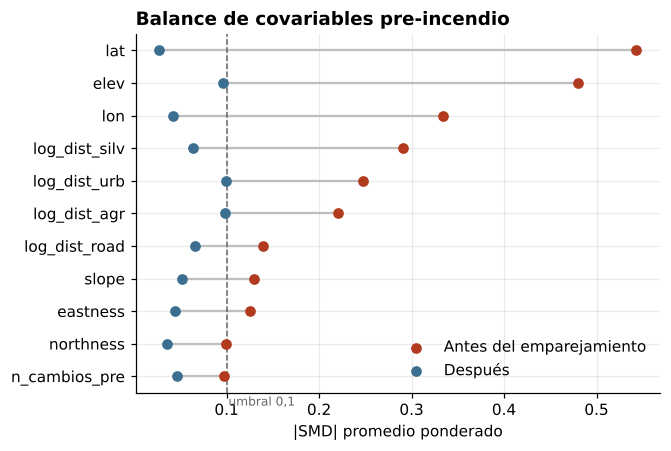

In [6]:
b = (bal.assign(w=bal.n_trat).groupby("covariable")
       .apply(lambda x: pd.Series({"Antes": np.average(x.SMD_antes.abs(), weights=x.w),
                                   "Después": np.average(x.SMD_despues.abs(), weights=x.w)}))
       .sort_values("Antes"))
fig, ax = plt.subplots(figsize=(6.2, 4.2))
y = np.arange(len(b))
ax.hlines(y, b["Después"], b["Antes"], color="0.75", lw=1.5)
ax.scatter(b["Antes"], y, color=C_TRAT, label="Antes del emparejamiento", zorder=3)
ax.scatter(b["Después"], y, color=C_CTRL, label="Después", zorder=3)
ax.axvline(0.1, ls="--", color="0.4", lw=1); ax.text(0.102, -0.9, "umbral 0,1", fontsize=8, color="0.4")
ax.set_yticks(y, b.index); ax.set_xlabel("|SMD| promedio ponderado")
ax.set_title("Balance de covariables pre-incendio", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG + "fig1_balance.png"); plt.show()
b.round(3).to_csv(RES + "balance.csv")

## 4. Resultado principal: estudio de eventos para el cambio a uso antrópico

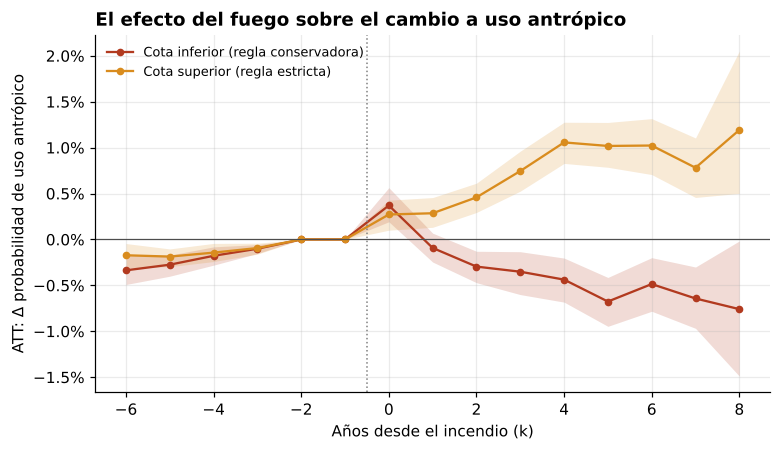

,k,ATT,EE,IC_inf,IC_sup,n_trat,n_bloques
0,-6,-0.0034,0.0009,-0.0049,-0.0017,57167,682
1,-5,-0.0027,0.0006,-0.0040,-0.0017,57167,682
2,-4,-0.0018,0.0005,-0.0028,-0.0008,57167,682
3,-3,-0.0010,0.0003,-0.0015,-0.0006,57167,682
4,-2,0.0000,0.0000,0.0000,0.0000,57167,682
5,-1,0.0000,0.0000,0.0000,0.0000,57167,682
6,0,0.0037,0.0010,0.0019,0.0056,57167,682
7,1,-0.0009,0.0008,-0.0025,0.0007,57167,682
8,2,-0.0030,0.0009,-0.0047,-0.0013,57167,682
9,3,-0.0035,0.0013,-0.0060,-0.0013,57167,682


In [7]:
R_PRINC = list(fc.RESULTADOS)[0]
es = {}
for regla in res:
    dif = fc.diferencias_por_tratado(df, res[regla]["pares"], fc.RESULTADOS[R_PRINC], k_min=-6, k_max=8)
    res[regla]["dif"] = dif
    es[regla] = fc.att_event_study(dif, n_boot=N_BOOT)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for regla, col, lab in [("conservadora", C_INF, "Cota inferior (regla conservadora)"),
                        ("estricta", C_SUP, "Cota superior (regla estricta)")]:
    e = es[regla]
    ax.fill_between(e.k, e.IC_inf, e.IC_sup, color=col, alpha=0.18, lw=0)
    ax.plot(e.k, e.ATT, "o-", color=col, ms=4, label=lab)
if verdad is not None:
    tv = att_verdadero(df, verdad, res["conservadora"]["pares"], fc.RESULTADOS[R_PRINC])
    ax.plot(tv.k, tv.ATT_verdadero, "k--", lw=1.3, label="Efecto verdadero (simulación)")
ax.axhline(0, color="0.3", lw=0.8); ax.axvline(-0.5, color="0.5", ls=":", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_xlabel("Años desde el incendio (k)"); ax.set_ylabel("ATT: Δ probabilidad de uso antrópico")
ax.set_title("El efecto del fuego sobre el cambio a uso antrópico", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.tight_layout(); fig.savefig(FIG + "fig2_event_study_principal.png"); plt.show()
pd.concat({k: v for k, v in es.items()}, names=["regla"]).round(5).to_csv(RES + "event_study_principal.csv")
es["conservadora"].round(4)

### 4.1 Efecto resumen (promedio k = 1…3, cohortes balanceadas) y comparación con el contraste ingenuo

In [8]:
filas = []
for regla in res:
    r = fc.att_promedio_post(res[regla]["dif"], *VENTANA_POST, n_boot=N_BOOT).iloc[0]
    filas.append({"Estimador": f"Emparejado, regla {regla}", "ATT": r.ATT, "IC 95% inf": r.IC_inf, "IC 95% sup": r.IC_sup})
COH_BAL = [g for g in COHORTES if g + VENTANA_POST[1] <= fc.LULC_Y1]
ing = np.mean([fc.ingenuo(df, fc.RESULTADOS[R_PRINC], cohortes=COH_BAL, k=k) for k in range(VENTANA_POST[0], VENTANA_POST[1] + 1)])
filas.append({"Estimador": "Ingenuo (quemado vs no quemado, sin control)", "ATT": ing, "IC 95% inf": np.nan, "IC 95% sup": np.nan})
if verdad is not None:
    tv = att_verdadero(df, verdad, res["conservadora"]["pares"], fc.RESULTADOS[R_PRINC])
    filas.append({"Estimador": "Verdadero (simulación)", "ATT": tv[tv.k.between(*VENTANA_POST)].ATT_verdadero.mean(),
                  "IC 95% inf": np.nan, "IC 95% sup": np.nan})
resumen = pd.DataFrame(filas)
resumen.to_csv(RES + "resumen_att.csv", index=False)
resumen.style.format({"ATT": "{:.2%}", "IC 95% inf": "{:.2%}", "IC 95% sup": "{:.2%}"}, na_rep="—")

,Estimador,ATT,IC 95% inf,IC 95% sup
0,"Emparejado, regla conservadora",-0.25%,-0.42%,-0.07%
1,"Emparejado, regla estricta",0.50%,0.36%,0.67%
2,"Ingenuo (quemado vs no quemado, sin control)",-0.11%,—,—


## 5. ¿A dónde van los píxeles quemados? Todos los destinos

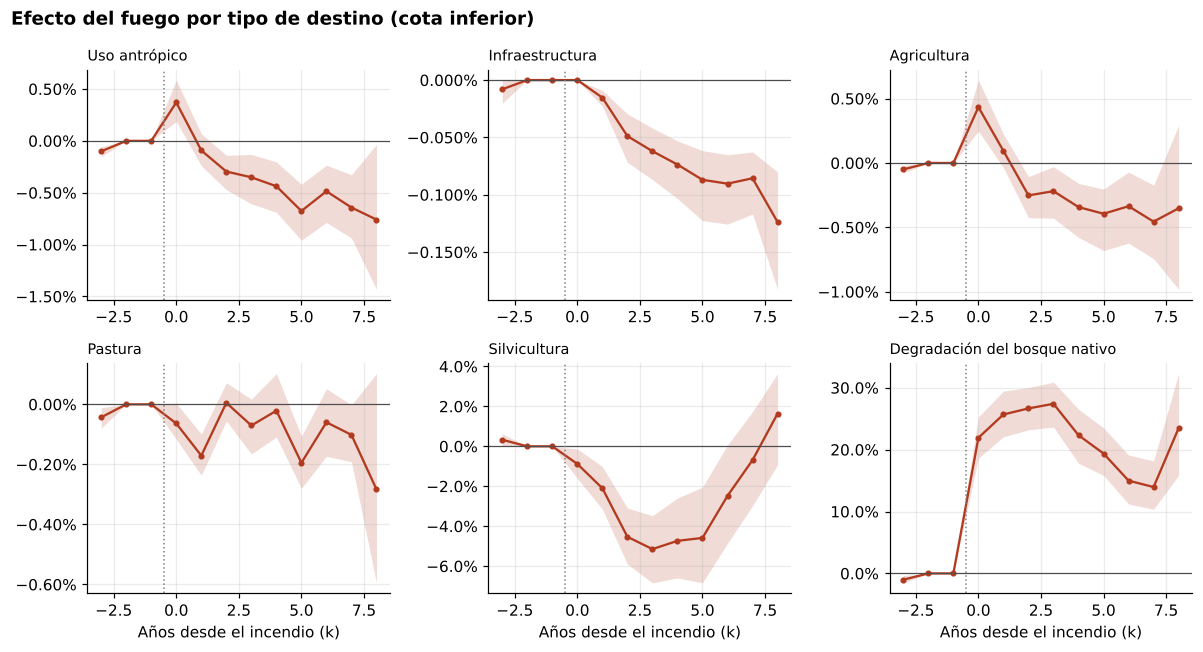

In [9]:
res_k = []
for nombre, s in fc.RESULTADOS.items():
    d = fc.diferencias_por_tratado(df, pares, s, k_min=-3, k_max=8)
    if nombre.startswith("Degradación"):
        d = d[d.grupo == "Bosque"]                  # degradación solo tiene sentido desde bosque
    e = fc.att_event_study(d, n_boot=150); e["resultado"] = nombre
    res_k.append(e)
res_k = pd.concat(res_k); res_k.to_csv(RES + "event_study_todos.csv", index=False)

nres = res_k.resultado.nunique(); ncol = 3; nfil = int(np.ceil(nres / ncol))
fig, axs = plt.subplots(nfil, ncol, figsize=(11, 3 * nfil), sharex=True)
for ax in axs.flat[nres:]: ax.axis("off")
for ax, (nombre, e) in zip(axs.flat, res_k.groupby("resultado", sort=False)):
    ax.fill_between(e.k, e.IC_inf, e.IC_sup, color=C_TRAT, alpha=0.18, lw=0)
    ax.plot(e.k, e.ATT, "o-", color=C_TRAT, ms=3)
    ax.axhline(0, color="0.3", lw=0.8); ax.axvline(-0.5, color="0.5", ls=":", lw=1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=None))
    ax.set_title("Degradación del bosque nativo" if nombre.startswith("Degradación") else nombre.split(" (")[0], fontsize=9.5, loc="left")
for ax in axs.flat[:nres]: ax.tick_params(labelbottom=True)
for ax in axs.flat[:nres][-ncol:]: ax.set_xlabel("Años desde el incendio (k)")
fig.suptitle("Efecto del fuego por tipo de destino (cota inferior)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG + "fig3_event_study_destinos.png"); plt.show()

### 5.1 Composición de trayectorias: quemados vs controles emparejados

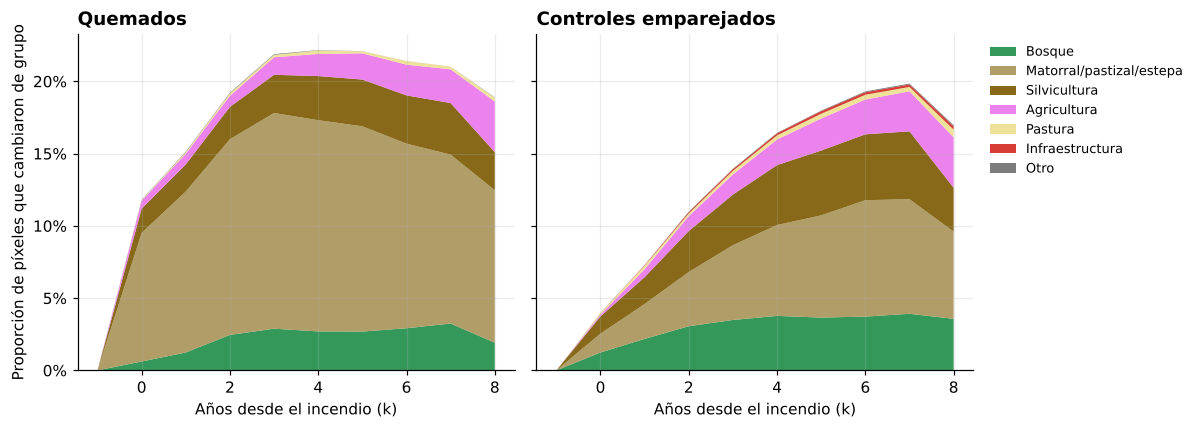

In [10]:
comp = fc.composicion(df, pares, k_max=8)
orden = list(fc.DESTINOS)
PALETA = {"Mismo grupo basal": "#C9C9C9", "Bosque": "#1F8D49", "Matorral/pastizal/estepa": "#A89358",
          "Matorral/pastizal": "#A89358", "Silvicultura": "#7A5900", "Agricultura": "#E974ED",
          "Mosaico agropecuario": "#E974ED", "Pastura": "#EDDE8E", "Infraestructura": "#D4271E", "Otro": "#6E6E6E"}
colores = [PALETA[d] for d in orden]
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, lado in zip(axs, ["Quemados", "Controles emparejados"]):
    t = comp[comp.lado == lado].pivot(index="k", columns="destino", values="proporcion")[orden]
    t = t.iloc[:, 1:]                                # se omite "mismo grupo" para ver los cambios
    ax.stackplot(t.index, t.T.values, labels=t.columns, colors=colores[1:], alpha=0.9)
    ax.set_title(lado, loc="left", fontweight="bold"); ax.set_xlabel("Años desde el incendio (k)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axs[0].set_ylabel("Proporción de píxeles que cambiaron de grupo")
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG + "fig4_composicion.png"); plt.show()

## 6. Heterogeneidad: ¿dónde abre más la puerta el fuego?

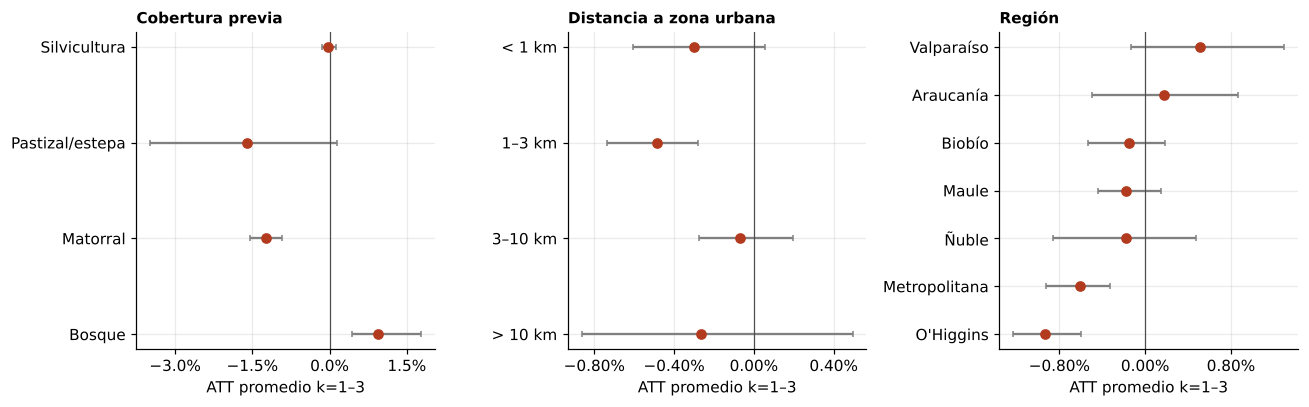

,ATT,EE,IC_inf,IC_sup,n_trat,n_bloques,Distancia a zona urbana (2012)
0,-0.0049,0.0011,-0.0074,-0.0028,19025,423,1–3 km
1,-0.0007,0.0012,-0.0027,0.0020,25268,429,3–10 km
2,-0.0030,0.0018,-0.0060,0.0005,8473,323,< 1 km
3,-0.0026,0.0036,-0.0086,0.0050,4401,128,> 10 km


In [11]:
dif = res["conservadora"]["dif"].copy()
dif["Distancia a zona urbana (2012)"] = pd.cut(dif["dist_urb"], [-1, 1000, 3000, 10000, np.inf],
                                              labels=["< 1 km", "1–3 km", "3–10 km", "> 10 km"])
het = {}
for col in ["grupo", "Distancia a zona urbana (2012)", "region"]:
    het[col] = fc.att_promedio_post(dif.dropna(subset=[col]), *VENTANA_POST, por=col, n_boot=200)
    het[col].to_csv(RES + f"heterogeneidad_{col.split()[0].lower()}.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
titulos = {"grupo": "Cobertura previa", "Distancia a zona urbana (2012)": "Distancia a zona urbana",
           "region": "Región"}
for ax, (col, h) in zip(axs, het.items()):
    if col == "region":
        h = h[h.n_trat >= 300].sort_values("ATT")
    elif col.startswith("Distancia"):
        orden_d = ["> 10 km", "3–10 km", "1–3 km", "< 1 km"]
        h = h.set_index(col).loc[[o for o in orden_d if o in set(h[col])]].reset_index()
    yy = np.arange(len(h))
    ax.errorbar(h.ATT, yy, xerr=[h.ATT - h.IC_inf, h.IC_sup - h.ATT], fmt="o", color=C_TRAT,
                ecolor="0.5", capsize=2)
    ax.set_yticks(yy, h[col].astype(str)); ax.axvline(0, color="0.3", lw=0.8)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(4))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=None))
    ax.set_title(titulos[col], loc="left", fontweight="bold", fontsize=10)
    ax.set_xlabel(f"ATT promedio k={VENTANA_POST[0]}–{VENTANA_POST[1]}")
fig.tight_layout(); fig.savefig(FIG + "fig5_heterogeneidad.png"); plt.show()
het["Distancia a zona urbana (2012)"].round(4)

## 7. Traducción a hectáreas

In [12]:
att_inf = resumen.loc[resumen.Estimador.str.contains("conservadora"), "ATT"].item()
att_sup = resumen.loc[resumen.Estimador.str.contains("estricta"), "ATT"].item()
if areas is not None:
    ha_elegibles = areas[areas.cohorte.isin(COH_BAL)].ha.sum()   # cohortes del efecto resumen
    q_ = df.fire_first.isin(COH_BAL)
    emp = pares.loc[pares.cohorte.isin(COH_BAL), "i_trat"].unique()
    w_emp = df.loc[emp, "w_muestral"].sum()
    frac_emparejada = w_emp / max(df.loc[q_, "w_muestral"].sum(), 1e-9)
    ha = ha_elegibles * frac_emparejada
    print(f"Área quemada elegible representada: {ha:,.0f} ha")
    print(f"Cohortes {min(COH_BAL)}–{max(COH_BAL)}. Conversión a uso antrópico atribuible al fuego (k={VENTANA_POST[0]}–{VENTANA_POST[1]}): "
          f"{fc.hectareas_atribuibles(att_inf, ha):,.0f} – {fc.hectareas_atribuibles(att_sup, ha):,.0f} ha")
else:
    print("Sin tabla de áreas (modo simulado): por cada 10.000 ha quemadas, el fuego explica entre "
          f"{att_inf*1e4:,.0f} y {att_sup*1e4:,.0f} ha adicionales de uso antrópico.")

Área quemada elegible representada: 709,891 ha
Cohortes 2014–2021. Conversión a uso antrópico atribuible al fuego (k=1–3): -1,749 – 3,523 ha


## 8. Validación del estimador (solo modo simulado)
En la simulación, el fuego cae más cerca de caminos y ciudades, donde de todos modos hay más conversión (confusión), y el filtro de Fuego borra las conversiones inmediatas (censura). La figura compara cada estimador con el efecto verdadero.

In [13]:
if verdad is not None:
    fig, ax = plt.subplots(figsize=(8.6, 3.4))
    r = resumen.iloc[::-1].reset_index(drop=True)
    cols = ["0.2" if "Verdadero" in s else ("0.65" if "Ingenuo" in s else C_TRAT) for s in r.Estimador]
    ax.barh(r.Estimador, r.ATT, color=cols, height=0.6)
    for i, (a, lo, hi) in enumerate(zip(r.ATT, r["IC 95% inf"], r["IC 95% sup"])):
        fin = a
        if not np.isnan(lo):
            ax.errorbar(a, i, xerr=[[a - lo], [hi - a]], color="k", lw=1.2, capsize=3)
            fin = hi
        ax.text(fin + 0.003, i, f"{a:.1%}", va="center", fontsize=9)
    ax.axvline(r.loc[r.Estimador.str.contains("Verdadero"), "ATT"].item(), color="0.2", ls="--", lw=1)
    ax.set_xlim(0, r[["ATT", "IC 95% sup"]].max().max() * 1.18)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlabel(f"ATT promedio k={VENTANA_POST[0]}–{VENTANA_POST[1]}")
    fig.suptitle("Validación: estimadores frente al efecto verdadero simulado",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); fig.savefig(FIG + "fig6_validacion_simulacion.png"); plt.show()
else:
    print("Modo real: esta validación se reporta desde la corrida simulada (anexo).")

Modo real: esta validación se reporta desde la corrida simulada (anexo).


## 9. Notas para el informe
* **Supuesto de identificación:** condicional a cobertura en *g−1* y *g−2*, región y covariables pre-incendio fijadas en 2012, la conversión esperada sin fuego es igual entre quemados y controles emparejados. El balance (Fig. 1) lo respalda.
* **Periodo pre:** con resultados absorbentes (infraestructura), los coeficientes pre-incendio son ~0 por construcción. Por eso la evidencia de validez descansa en el balance, la estabilidad previa (`n_cambios_pre`) y la simulación.
* **Inferencia:** el bootstrap por bloques re-muestrea tratados con sus controles fijos, sin re-emparejar. Es una aproximación conservadora estándar en la literatura de *land-system science*.
* **Limitaciones:** el producto Fuego parte en 2013 (no hay historia previa de quemas); la cobertura llega a 2024, así que las cohortes recientes tienen menos años de seguimiento; los errores de clasificación de MapBiomas entran como ruido en ambos grupos.